<a href="https://colab.research.google.com/github/yang200212/MSSP-6070/blob/main/Modules/Week_7/PARTICIPATION_ACTIVITY_Week_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import os
import subprocess
from pathlib import Path

owner = 'yang200212'
repository = 'MSSP-6070'

repo_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

# Clone the repository
if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists.")

# Set working directory
os.chdir(repo_path)
print("Current directory:", os.getcwd())

Repository already exists.
Current directory: /content/MSSP-6070


In [12]:
# Update local repository with latest GitHub files
subprocess.run(
    ['git', '-C', str(repo_path), 'pull', '--ff-only', 'origin', 'main'],
    check=True
)

CompletedProcess(args=['git', '-C', '/content/MSSP-6070', 'pull', '--ff-only', 'origin', 'main'], returncode=0)

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define dataset path
DATA_PATH = repo_path / 'Modules' / 'Week_7' / 'InternetSales.csv'

# Check whether the file exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Data file not found: {DATA_PATH}"
    )

# Load the CSV dataset
sales = pd.read_csv(DATA_PATH, encoding='cp1252')

# Confirm successful loading
print("Data loaded successfully!")
print("Data shape:", sales.shape)
display(sales.head())

Data loaded successfully!
Data shape: (60398, 60)


/tmp/ipykernel_1710/1718102657.py:15: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  sales = pd.read_csv(DATA_PATH, encoding='cp1252')


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


Yearly Sales:
Year
2010    4.342104e+04
2011    7.075526e+06
2012    5.842485e+06
2013    1.635155e+07
2014    4.569472e+04
Name: SalesAmount, dtype: float64


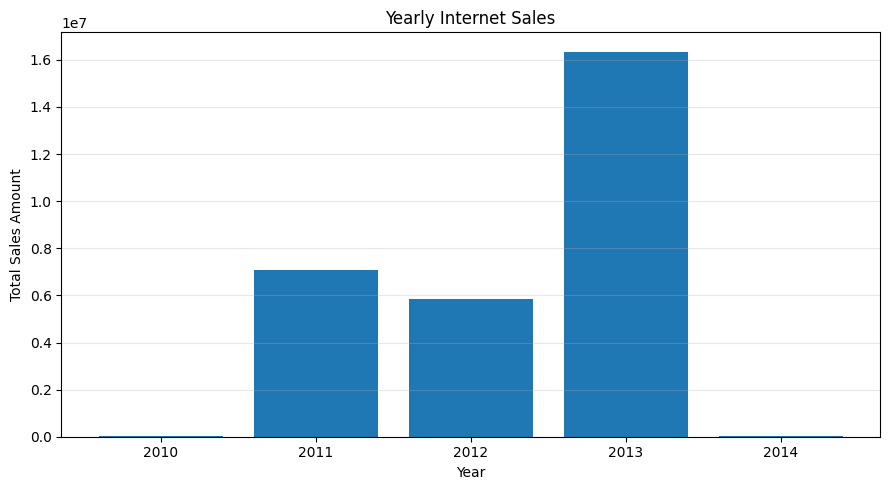

Figure saved successfully!


In [14]:
sales['OrderDate'] = pd.to_datetime(sales['OrderDate'])
sales['Year'] = sales['OrderDate'].dt.year

yearly_sales = sales.groupby('Year')['SalesAmount'].sum()

print("Yearly Sales:")
print(yearly_sales)

# create bar chart
plt.figure(figsize=(9, 5))
plt.bar(yearly_sales.index.astype(str), yearly_sales.values)

plt.title('Yearly Internet Sales')
plt.xlabel('Year')
plt.ylabel('Total Sales Amount')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

# save bar chart as PDF
plt.savefig('Yearly_Internet_Sales.pdf',
            format='pdf',
            bbox_inches='tight')

plt.show()
print("Figure saved successfully!")
